<a href="https://colab.research.google.com/github/GavinShenTJU/hello-world/blob/master/codes/Mini_Word_Embedding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pylab as plt
import pandas as pd
import torch
from torch import nn
from torch import optim
import torch.nn.functional as F
from torchvision import datasets, transforms, models
from torch.utils.data import Dataset, DataLoader
import random
!pip install tensorflow --quiet
from tensorflow.keras.preprocessing.text import one_hot
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.preprocessing import OneHotEncoder
!pip install torchsummaryX  --quiet
from torchsummaryX import summary

# Data - Preprocessing - Steps : Visualization

<img src="https://cdn-images-1.medium.com/max/800/1*SANI-0E8qSTHzGHg4HHtNA.png">
<img src="https://cdn-images-1.medium.com/max/1200/0*dEB7_sqWOHhV82EI.png">

# Dataset Source
<img src="https://github.com/bala-codes/Mini_Word_Embeddings/blob/master/codes/Capture.PNG?raw=true">


<img src="https://cdn-images-1.medium.com/max/800/1*pDeswCr7eBhEDtiywMkAqQ.png">
<img src="https://cdn-images-1.medium.com/max/800/1*SANI-0E8qSTHzGHg4HHtNA.png">
<img src="https://cdn-images-1.medium.com/max/1200/1*r_9zfDywyD1TbVpxKENHjw.png">

In [3]:
# Sample Document # Recreated from the tom and jerry cartoon

docs = ["cat and mice are buddies",
        'mice lives in hole',
        'cat lives in house',
        'cat chases mice',
        'cat catches mice',
        'cat eats mice',
        'mice runs into hole',
        'cat says bad words',
        'cat and mice are pals',
        'cat and mice are chums',
        'mice stores food in hole',
        'cat stores food in house',
        'mice sleeps in hole',
        'cat sleeps in house']

In [4]:
idx_2_word = {}
word_2_idx = {}
temp = []
i = 1
for doc in docs:
  for word in doc.split():
    if word not in temp:
      temp.append(word)
      idx_2_word[i] = word
      word_2_idx[word] = i
      i += 1

print(idx_2_word)
print(word_2_idx)

{1: 'cat', 2: 'and', 3: 'mice', 4: 'are', 5: 'buddies', 6: 'lives', 7: 'in', 8: 'hole', 9: 'house', 10: 'chases', 11: 'catches', 12: 'eats', 13: 'runs', 14: 'into', 15: 'says', 16: 'bad', 17: 'words', 18: 'pals', 19: 'chums', 20: 'stores', 21: 'food', 22: 'sleeps'}
{'cat': 1, 'and': 2, 'mice': 3, 'are': 4, 'buddies': 5, 'lives': 6, 'in': 7, 'hole': 8, 'house': 9, 'chases': 10, 'catches': 11, 'eats': 12, 'runs': 13, 'into': 14, 'says': 15, 'bad': 16, 'words': 17, 'pals': 18, 'chums': 19, 'stores': 20, 'food': 21, 'sleeps': 22}


# Words to numbers

In [5]:
vocab_size = 25

def one_hot_map(doc):
  x = []
  for word in doc.split():
    x.append(word_2_idx[word])
  return x

encoded_docs = [one_hot_map(d) for d in docs]
encoded_docs

[[1, 2, 3, 4, 5],
 [3, 6, 7, 8],
 [1, 6, 7, 9],
 [1, 10, 3],
 [1, 11, 3],
 [1, 12, 3],
 [3, 13, 14, 8],
 [1, 15, 16, 17],
 [1, 2, 3, 4, 18],
 [1, 2, 3, 4, 19],
 [3, 20, 21, 7, 8],
 [1, 20, 21, 7, 9],
 [3, 22, 7, 8],
 [1, 22, 7, 9]]

# Padding

In [6]:
max_len = 10
padded_docs = pad_sequences(encoded_docs, maxlen=max_len, padding='post')
padded_docs

array([[ 1,  2,  3,  4,  5,  0,  0,  0,  0,  0],
       [ 3,  6,  7,  8,  0,  0,  0,  0,  0,  0],
       [ 1,  6,  7,  9,  0,  0,  0,  0,  0,  0],
       [ 1, 10,  3,  0,  0,  0,  0,  0,  0,  0],
       [ 1, 11,  3,  0,  0,  0,  0,  0,  0,  0],
       [ 1, 12,  3,  0,  0,  0,  0,  0,  0,  0],
       [ 3, 13, 14,  8,  0,  0,  0,  0,  0,  0],
       [ 1, 15, 16, 17,  0,  0,  0,  0,  0,  0],
       [ 1,  2,  3,  4, 18,  0,  0,  0,  0,  0],
       [ 1,  2,  3,  4, 19,  0,  0,  0,  0,  0],
       [ 3, 20, 21,  7,  8,  0,  0,  0,  0,  0],
       [ 1, 20, 21,  7,  9,  0,  0,  0,  0,  0],
       [ 3, 22,  7,  8,  0,  0,  0,  0,  0,  0],
       [ 1, 22,  7,  9,  0,  0,  0,  0,  0,  0]], dtype=int32)

# Creating dataset tuples for training

In [7]:
training_data = np.empty((0,2))

window = 2
for sentence in padded_docs:
  sent_len = len(sentence)
  for i, word in enumerate(sentence):
    w_context = []
    if sentence[i] != 0:
      w_target = sentence[i]
      for j in range(i-window, i + window + 1):
        if j != i and j <= sent_len -1 and j >=0 and sentence[j]!=0:
          w_context = sentence[j]
          training_data = np.append(training_data, [[w_target, w_context]], axis=0)
          #training_data.append([w_target, w_context])

print(len(training_data))
print(training_data.shape)
training_data

148
(148, 2)


array([[ 1.,  2.],
       [ 1.,  3.],
       [ 2.,  1.],
       [ 2.,  3.],
       [ 2.,  4.],
       [ 3.,  1.],
       [ 3.,  2.],
       [ 3.,  4.],
       [ 3.,  5.],
       [ 4.,  2.],
       [ 4.,  3.],
       [ 4.,  5.],
       [ 5.,  3.],
       [ 5.,  4.],
       [ 3.,  6.],
       [ 3.,  7.],
       [ 6.,  3.],
       [ 6.,  7.],
       [ 6.,  8.],
       [ 7.,  3.],
       [ 7.,  6.],
       [ 7.,  8.],
       [ 8.,  6.],
       [ 8.,  7.],
       [ 1.,  6.],
       [ 1.,  7.],
       [ 6.,  1.],
       [ 6.,  7.],
       [ 6.,  9.],
       [ 7.,  1.],
       [ 7.,  6.],
       [ 7.,  9.],
       [ 9.,  6.],
       [ 9.,  7.],
       [ 1., 10.],
       [ 1.,  3.],
       [10.,  1.],
       [10.,  3.],
       [ 3.,  1.],
       [ 3., 10.],
       [ 1., 11.],
       [ 1.,  3.],
       [11.,  1.],
       [11.,  3.],
       [ 3.,  1.],
       [ 3., 11.],
       [ 1., 12.],
       [ 1.,  3.],
       [12.,  1.],
       [12.,  3.],
       [ 3.,  1.],
       [ 3., 12.],
       [ 3.,

In [8]:
enc = OneHotEncoder()
enc.fit(np.array(range(30)).reshape(-1,1)) # -1表示自动计算行数
onehot_label_x = enc.transform(training_data[:,0].reshape(-1,1)).toarray()
onehot_label_x

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [9]:
enc = OneHotEncoder()
enc.fit(np.array(range(30)).reshape(-1,1))
onehot_label_y = enc.transform(training_data[:,1].reshape(-1,1)).toarray()
onehot_label_y

array([[0., 0., 1., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 1., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [10]:
print(onehot_label_x[0])
print(onehot_label_y[0])

# From Numpy to Torch

# onehot_label_x = torch.from_numpy(onehot_label_x) # Removed redundant conversion
# onehot_label_y = torch.from_numpy(onehot_label_y) # Removed redundant conversion

# Ensure they are tensors and convert to float32 for training if not already
onehot_label_x = torch.tensor(onehot_label_x, dtype=torch.float32)
onehot_label_y = torch.tensor(onehot_label_y, dtype=torch.float32)

print(onehot_label_x.shape, onehot_label_y.shape)

[0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
[0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
torch.Size([148, 30]) torch.Size([148, 30])


<img src="https://cdn-images-1.medium.com/max/800/1*rb9i3dT_rH3DB31atto_Ag.png">

In [11]:
class WEMB(nn.Module):
  def __init__(self, input_size, hidden_size):
    super(WEMB, self).__init__()
    self.input_size = input_size
    self.hidden_size = hidden_size
    self.softmax = nn.Softmax(dim=1)

    self.l1 = nn.Linear(self.input_size, self.hidden_size, bias=False)
    self.l2 = nn.Linear(self.hidden_size, self.input_size, bias=False)

  def forward(self, x):
    out_bn = self.l1(x) # bn - bottle_neck
    out = self.l2(out_bn)
    out = self.softmax(out)
    return out, out_bn

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [ ]:
'''
m = nn.Softmax() #nn.Sigmoid()
loss = nn.BCELoss()
input = torch.tensor([0.9,0.0,0.0]) #torch.randn(3, requires_grad=True)
target = torch.tensor([1.0,0.0,0.0])
output = loss(m(input), target)
print(input, m(input), target) tensor([0.9000, 0.0000, 0.0000]) tensor([0.5515, 0.2242, 0.2242]) tensor([1., 0., 0.])
output -> 0.36
'''

'''
m = nn.Sigmoid()
loss = nn.BCELoss()
input = torch.tensor([0.9,0.0,0.0])
target = torch.tensor([1.0,0.0,0.0])
output = loss(m(input), target)
print(input, m(input), target) tensor([0.9000, 0.0000, 0.0000]) tensor([0.7109, 0.5000, 0.5000]) tensor([1., 0., 0.])
output -> 0.5758
'''

'\nm = nn.Sigmoid()\nloss = nn.BCELoss()\ninput = torch.tensor([0.9,0.0,0.0])\ntarget = torch.tensor([1.0,0.0,0.0])\noutput = loss(m(input), target)\nprint(input, m(input), target) tensor([0.9000, 0.0000, 0.0000]) tensor([0.7109, 0.5000, 0.5000]) tensor([1., 0., 0.])\noutput -> 0.5758\n'

In [14]:
input_size = 30
hidden_size = 2
learning_rate = 0.01
num_epochs = 10000

untrained_model = WEMB(input_size, hidden_size).to(device)
model = WEMB(input_size, hidden_size).to(device)
model.train(True)
print(model)
print()

# Loss and optimizer
criterion = nn.BCELoss()
#optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0, dampening=0, weight_decay=0, nesterov=False)
# summary(model, torch.ones((1,30)).to(device)) # Commented out due to internal TypeError in torchsummaryX

WEMB(
  (softmax): Softmax(dim=1)
  (l1): Linear(in_features=30, out_features=2, bias=False)
  (l2): Linear(in_features=2, out_features=30, bias=False)
)



Epoch [100/10000], Loss: 0.1437
Epoch [200/10000], Loss: 0.1424
Epoch [300/10000], Loss: 0.1406
Epoch [400/10000], Loss: 0.1382
Epoch [500/10000], Loss: 0.1348
Epoch [600/10000], Loss: 0.1301
Epoch [700/10000], Loss: 0.1238
Epoch [800/10000], Loss: 0.1156
Epoch [900/10000], Loss: 0.1054
Epoch [1000/10000], Loss: 0.0935
Epoch [1100/10000], Loss: 0.0806
Epoch [1200/10000], Loss: 0.0679
Epoch [1300/10000], Loss: 0.0570
Epoch [1400/10000], Loss: 0.0491
Epoch [1500/10000], Loss: 0.0440
Epoch [1600/10000], Loss: 0.0409
Epoch [1700/10000], Loss: 0.0392
Epoch [1800/10000], Loss: 0.0384
Epoch [1900/10000], Loss: 0.0381
Epoch [2000/10000], Loss: 0.0382
Epoch [2100/10000], Loss: 0.0384
Epoch [2200/10000], Loss: 0.0389
Epoch [2300/10000], Loss: 0.0393
Epoch [2400/10000], Loss: 0.0399
Epoch [2500/10000], Loss: 0.0404
Epoch [2600/10000], Loss: 0.0410
Epoch [2700/10000], Loss: 0.0415
Epoch [2800/10000], Loss: 0.0420
Epoch [2900/10000], Loss: 0.0425
Epoch [3000/10000], Loss: 0.0429
Epoch [3100/10000],

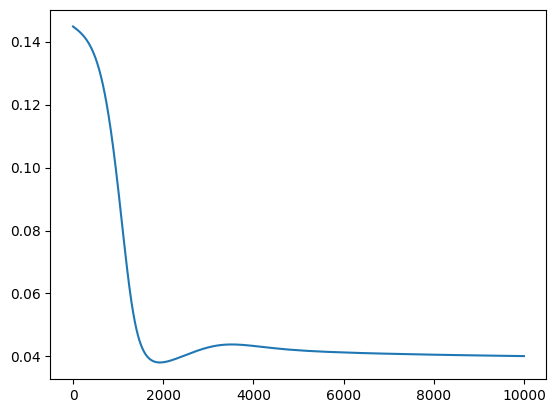

In [15]:
loss_val = []
onehot_label_x = onehot_label_x.to(device)
onehot_label_y = onehot_label_y.to(device)

for epoch in range(num_epochs):
  for i in range(onehot_label_y.shape[0]):
      inputs = onehot_label_x[i].float()
      labels = onehot_label_y[i].float()
      inputs = inputs.unsqueeze(0)
      labels = labels.unsqueeze(0)

      # Forward pass
      output, wemb = model(inputs)
      loss = criterion(output, labels)

      # Backward and optimize
      optimizer.zero_grad()
      loss.backward()
      optimizer.step()
  loss_val.append(loss.item())

  if (epoch+1) % 100 == 0:
    print (f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

plt.plot(loss_val)

In [17]:
docs = ['cat and mice are buddies hole lives in house chases catches runs into says bad words pals chums stores sleeps']
encoded_docs = [one_hot_map(d) for d in docs]

test_arr = np.array([[ 1.,  2., 3., 4., 5., 8., 6., 7., 9., 10., 11., 13., 14., 15., 16., 17., 18., 19., 20., 22.]])
test = enc.transform(test_arr.reshape(-1,1)).toarray()

output = []
for i in range(test.shape[0]):
  _, wemb2 = model(torch.from_numpy(test[i]).unsqueeze(0).float().to(device))
  wemb2 = wemb2[0].detach().cpu().numpy()
  output.append(wemb2)
print(len(output))
print(output)

20
[array([-0.11341406, -0.5372298 ], dtype=float32), array([ 0.21377628, -1.9415538 ], dtype=float32), array([-0.17481357, -0.5553911 ], dtype=float32), array([ 1.8504242, -1.6224467], dtype=float32), array([ 0.9675472, -2.1999416], dtype=float32), array([-2.7785304,  1.9302487], dtype=float32), array([-2.677465 , -2.0397058], dtype=float32), array([-1.3041868, -0.9190544], dtype=float32), array([-3.1536188 ,  0.87576675], dtype=float32), array([-0.79926234, -2.4025128 ], dtype=float32), array([-0.8204975, -2.423133 ], dtype=float32), array([-0.7097373, -0.6259591], dtype=float32), array([-0.7143085, -0.6300204], dtype=float32), array([ 1.2592049 , -0.55726516], dtype=float32), array([ 1.3169074 , -0.59732115], dtype=float32), array([2.825714 , 0.7125152], dtype=float32), array([ 0.9845991, -2.20925  ], dtype=float32), array([ 0.9877051, -2.2129123], dtype=float32), array([-2.4638748, -1.7609807], dtype=float32), array([-2.6774838, -2.039688 ], dtype=float32)]


In [18]:
docs = ['cat', 'and', 'mice', 'are', 'buddies', 'hole', 'lives', 'in', 'house', 'chases', 'catches', 'runs', 'into', 'says', 'bad', 'words', 'pals', 'chums', 'stores', 'sleeps']
for i in range(0, len(docs)):
  print("Word - {} - It's Word Embeddings : {:.3} & {:.3} -".format(docs[i], output[i][0], output[j][0]))

Word - cat - It's Word Embeddings : -0.113 & -2.78 -
Word - and - It's Word Embeddings : 0.214 & -2.78 -
Word - mice - It's Word Embeddings : -0.175 & -2.78 -
Word - are - It's Word Embeddings : 1.85 & -2.78 -
Word - buddies - It's Word Embeddings : 0.968 & -2.78 -
Word - hole - It's Word Embeddings : -2.78 & -2.78 -
Word - lives - It's Word Embeddings : -2.68 & -2.78 -
Word - in - It's Word Embeddings : -1.3 & -2.78 -
Word - house - It's Word Embeddings : -3.15 & -2.78 -
Word - chases - It's Word Embeddings : -0.799 & -2.78 -
Word - catches - It's Word Embeddings : -0.82 & -2.78 -
Word - runs - It's Word Embeddings : -0.71 & -2.78 -
Word - into - It's Word Embeddings : -0.714 & -2.78 -
Word - says - It's Word Embeddings : 1.26 & -2.78 -
Word - bad - It's Word Embeddings : 1.32 & -2.78 -
Word - words - It's Word Embeddings : 2.83 & -2.78 -
Word - pals - It's Word Embeddings : 0.985 & -2.78 -
Word - chums - It's Word Embeddings : 0.988 & -2.78 -
Word - stores - It's Word Embeddings : -2

[np.float32(-0.113414064), np.float32(0.21377628), np.float32(-0.17481357), np.float32(1.8504242), np.float32(0.9675472), np.float32(-2.7785304), np.float32(-2.677465), np.float32(-1.3041868), np.float32(-3.1536188), np.float32(-0.79926234), np.float32(-0.8204975), np.float32(-0.7097373), np.float32(-0.7143085), np.float32(1.2592049), np.float32(1.3169074), np.float32(2.825714), np.float32(0.9845991), np.float32(0.9877051), np.float32(-2.4638748), np.float32(-2.6774838)] [np.float32(-0.5372298), np.float32(-1.9415538), np.float32(-0.5553911), np.float32(-1.6224467), np.float32(-2.1999416), np.float32(1.9302487), np.float32(-2.0397058), np.float32(-0.9190544), np.float32(0.87576675), np.float32(-2.4025128), np.float32(-2.423133), np.float32(-0.6259591), np.float32(-0.6300204), np.float32(-0.55726516), np.float32(-0.59732115), np.float32(0.7125152), np.float32(-2.20925), np.float32(-2.2129123), np.float32(-1.7609807), np.float32(-2.039688)]


<Figure size 640x480 with 0 Axes>

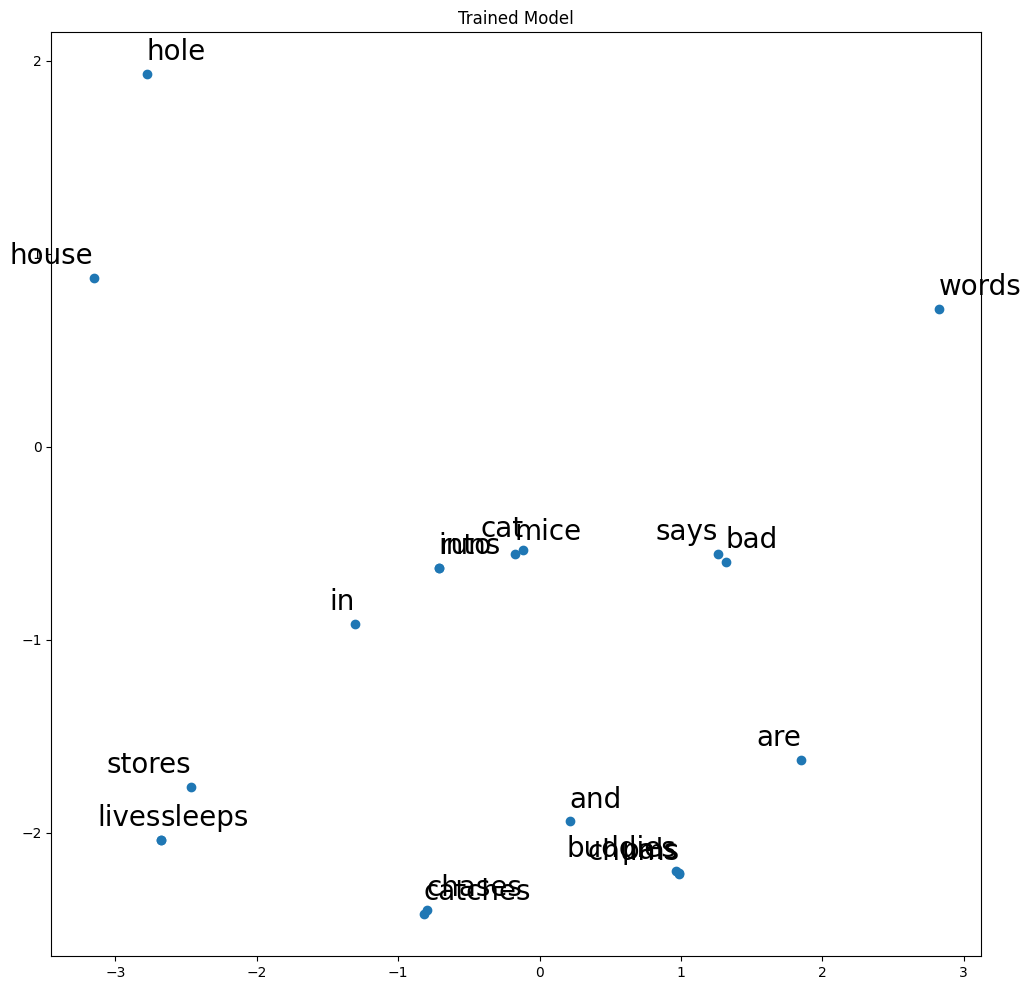

In [19]:
xs = []
ys = []
for i in range(len(output)):
  xs.append(output[i][0])
  ys.append(output[i][1])
print(xs, ys)

docs = ['cat', 'and', 'mice', 'are', 'buddies', 'hole', 'lives', 'in', 'house', 'chases', 'catches', 'runs', 'into', 'says', 'bad', 'words', 'pals', \
        'chums', 'stores', 'sleeps']

plt.clf()
plt.figure(figsize=(12,12))
plt.scatter(xs,ys)
label = docs

for i,(x,y) in enumerate(zip(xs,ys)):
  plt.annotate(label[i], (x,y), textcoords="offset points", xytext=(0,10), fontsize=20, ha = random.choice(['left', 'right']))
  plt.title("Trained Model")
plt.show()

In [20]:
import plotly
import plotly.express as px

import plotly.express as px
fig = px.scatter(x=xs, y=ys, text=docs, size_max=100)
fig.update_traces(textposition= random.choice(['top center', 'bottom center','bottom left']))
fig.update_layout(height=800,title_text='Custom Word Embeddings')
fig.show()

# How Untrained Model behaves with our data

20
[array([-0.04275345, -0.02886879], dtype=float32), array([-0.15202194,  0.07314789], dtype=float32), array([ 0.11291146, -0.02519633], dtype=float32), array([-0.15067662, -0.03637494], dtype=float32), array([-0.12090125, -0.12671636], dtype=float32), array([-0.05830668, -0.06250159], dtype=float32), array([ 0.11598429, -0.17297596], dtype=float32), array([ 0.07779913, -0.16202387], dtype=float32), array([ 0.09326096, -0.08127425], dtype=float32), array([0.00153296, 0.10262998], dtype=float32), array([-0.11948875, -0.08580889], dtype=float32), array([-0.07129273,  0.11963926], dtype=float32), array([ 0.03983977, -0.10740042], dtype=float32), array([0.10391836, 0.05241726], dtype=float32), array([ 0.15077467, -0.16078997], dtype=float32), array([ 0.16935094, -0.10312367], dtype=float32), array([-0.07607429,  0.14855856], dtype=float32), array([-0.12368356,  0.07868253], dtype=float32), array([-0.01665527, -0.15915565], dtype=float32), array([0.12776056, 0.09338955], dtype=float32)]
[-

<Figure size 432x288 with 0 Axes>

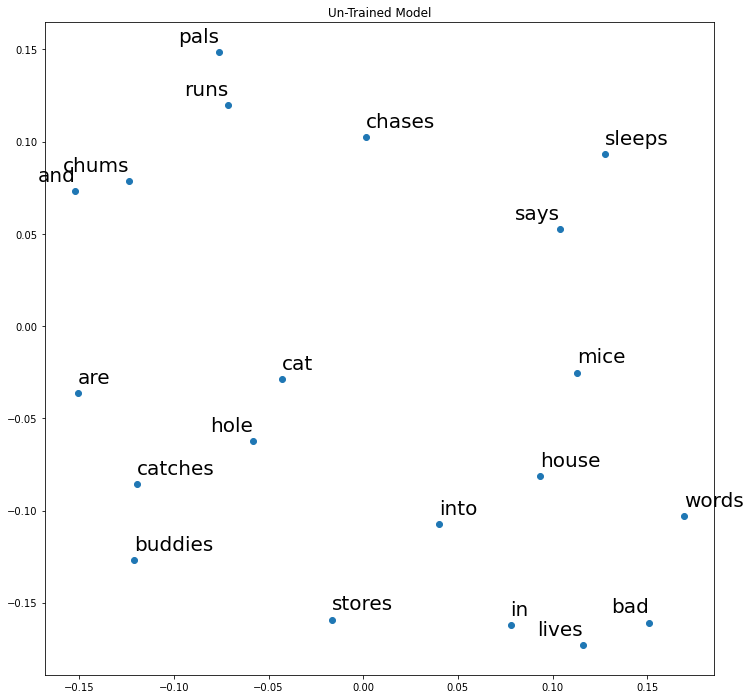

In [ ]:
output = []
for i in range(test.shape[0]):
  _, wemb2 = untrained_model(torch.from_numpy(test[i]).unsqueeze(0).float()) # Here I am loading the untrained model
  wemb2 = wemb2[0].detach().cpu().numpy()
  output.append(wemb2)
print(len(output))
print(output)

xs = []
ys = []
for i in range(len(output)):
  xs.append(output[i][0])
  ys.append(output[i][1])
print(xs, ys)

docs = ['cat', 'and', 'mice', 'are', 'buddies', 'hole', 'lives', 'in', 'house', 'chases', 'catches', 'runs', 'into', 'says', 'bad', 'words', 'pals', \
        'chums', 'stores', 'sleeps']

plt.clf()
plt.figure(figsize=(12,12))
plt.scatter(xs,ys)
label = docs

for i,(x,y) in enumerate(zip(xs,ys)):
  plt.annotate(label[i], (x,y), textcoords="offset points", xytext=(0,10), fontsize=20, ha = random.choice(['left', 'right']))
  plt.title("Un-Trained Model")
plt.show()

In [ ]:
import plotly
import plotly.express as px

import plotly.express as px
fig = px.scatter(x=xs, y=ys, text=docs, size_max=100)
fig.update_traces(textposition= random.choice(['top center', 'bottom center','bottom left']))
fig.update_layout(height=800,title_text='Custom Word Embeddings')
fig.show()